### APS1070 Project 1 --- Basic Principles and Models
**Deadline: Oct 4th, 11PM - 10 percent**

**Academic Integrity**

This project is individual - it is to be completed on your own. If you have questions, please post your query in the APS1070 Piazza Q&A forums (the answer might be useful to others!).

Do not share your code with others, or post your work online. Do not submit code that you have not written yourself without proper acknowledgment of the source, including generated code (please refer to the course syllabus). Students suspected of plagiarism on a project, midterm or exam will be referred to the department for formal discipline for breaches of the Student Code of Conduct.

Name: **Tiffany Costas**  *(here and elsewhere, please replace the underscore with your answer)*

Student ID: **1005854844**

##**Marking Scheme:**

This project is worth **10 percent** of your final grade.

Draw a plot or table where necessary to summarize your findings.

**Practice Vectorized coding**: If you need to write a loop in your solution, think about how you can implement the same functionality with vectorized operations. Try to avoid loops as much as possible (in some cases, loops are inevitable).




### How to submit **(HTML + IPYNB)**

1. Check that the completed `.ipynb` file runs correctly when using `Runtime -> Run All`.

2. Download your notebook: `File -> Download .ipynb`

3. Click on the Files icon on the far left menu of Colab

4. Select & upload your `.ipynb` file you just downloaded, and then obtain its path (right click) (you might need to hit the Refresh button before your file shows up)


5. execute the following in a Colab cell:
```
%%shell
jupyter nbconvert --to html /PATH/TO/YOUR/NOTEBOOKFILE.ipynb
```

6. An HTML version of your notebook will appear in the files, so you can download it.

7. Submit **both** <font color='red'>`HTML` and `IPYNB`</font>  files on Quercus for grading.



Ref: https://stackoverflow.com/a/64487858



# Project 1 [10 Marks]
Let's apply the tools we have learned in the tutorial to a new dataset.

We're going to work with the [California housing dataset](https://inria.github.io/scikit-learn-mooc/python_scripts/datasets_california_housing.html). This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block group is the smallest geographical unit for which the U.S. Census Bureau publishes sample data (a block group typically has a population
of 600 to 3,000 people). The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).


Download the dataset using the cells below:

In [1]:
from sklearn.datasets import fetch_california_housing
import numpy as np
import matplotlib.pyplot as plt
dataset = fetch_california_housing()

## Part 1: Getting started [2.5 Marks]
First off, take a look at the `data`, `target` and `feature_names` entries in the `dataset` dictionary. They contain the information we'll be working with here. Then, create a Pandas DataFrame called `df` containing the data and the targets, with the feature names as column headings. If you need help, see [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.html) for more details on how to achieve this. **[0.4]**

* How many features do we have in this dataset? **_8_**
* Determine the median target value. **_1.797_**
* How many individuals have a target value greater than the median target value? **_10317_**


Now add an additional column containing either 0 (if the target value is below the median or equal to the median) or 1 (if the target value is greater than the median). This will be the new target value to classify the data as images with a digit below median or above median. **[0.5]**

In [3]:
### YOUR CODE HERE ###
data = dataset.data
target = dataset.target
feature_names = dataset.feature_names
print("Number of features: ", len(feature_names))
median_target = np.median(target)
print("Median target value: ", median_target)
print("Individuals with target value greater than median: ", np.count_nonzero(target > np.median(target)))

import pandas as pd
df = pd.DataFrame(data, columns=feature_names)
df['MedHouseVal'] = target
df.loc[:,'Target']= [1 if val > np.median(target) else 0 for val in target]
df.head()

Number of features:  8
Median target value:  1.797
Individuals with target value greater than median:  10317


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,1
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,1
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,1
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,1
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,1


### Splitting the data
It is best practice to have a training set (from which there is a rotating validation subset) and a test set. Our aim here is to (eventually) obtain the best accuracy we can on the test set (we'll do all our tuning on the training/validation sets, however.)

**Split the dataset** into a train and a test set **"70:30"**, use **``random_state=1``**. The test set is set aside (untouched) for final evaluation, once hyperparameter optimization is complete. **[0.5]**

**Only Split the dataset once within you notebook.** You should not use the `train_test_split` function more than once, regardless of the random state. Keep this in mind for your future projects as well.

In [4]:
### YOUR CODE HERE -  ###
from sklearn.model_selection import train_test_split
x = df.drop(['MedHouseVal', 'Target'], axis=1) #removing target/y-values from dataframe
y = df['Target'] #target/y-values
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=1)

### Effect of Standardization (Visual)
Use `seaborn.lmplot` ([help here](https://seaborn.pydata.org/generated/seaborn.lmplot.html)) to visualize a few features of the training set. Draw a plot where the x-axis is `Population`, and the y-axis is `Latitude`, and the color of each datapoint indicates its class.  **[0.5]**

Standardizing the data is often critical in machine learning. Show a plot as above, but standardize the two features. What's different? **why do they look similar?** Based on your observation, what is the advantage of standardization? **[0.6]**

**Answer: The difference between the two graphs are the x and y axis values, as the general shape/distribution of the two look similar. Standardizing the values brought the population values between 0-30 (compared to 0-35000) whereas latitude values now range from -1 to 3. The advantage of standardization is that it transforms the data to have a mean of 0 and standard deviation of 1 for all features.  Without standardizing them, the features with larger scales will take precedance influencing the model. This helps reduce any bias caused by the original scaling since KNN is scale sensitive as it measures distance between points.**




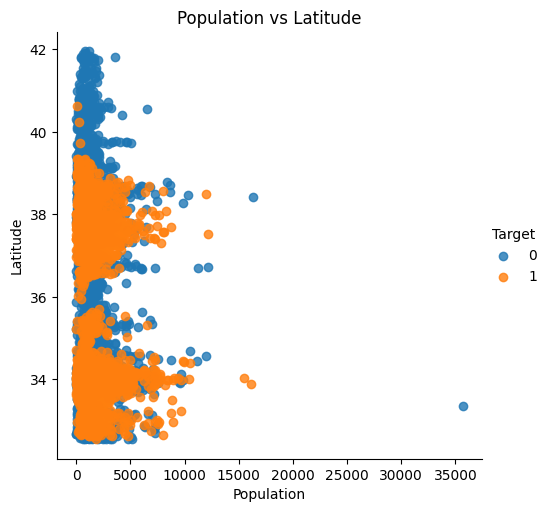

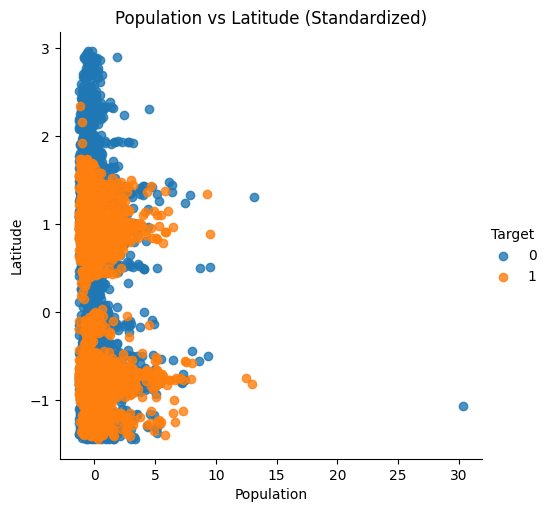

-3.221245099133898e-17
2.461916483399129e-15
1.0000000000000002
1.000000000000006


In [5]:
### YOUR CODE HERE ###
x_train_df = pd.DataFrame(x_train, columns=feature_names)
x_train_df['Target'] = y_train
x_test_df = pd.DataFrame(x_test, columns=feature_names)
x_test_df['Target'] = y_test

import seaborn
seaborn.lmplot(
    data=x_train_df,
    x="Population",
    y="Latitude",
    hue="Target",
    fit_reg=False
)
plt.title("Population vs Latitude")
plt.show()

df_standardize = x_train_df.copy()
#Standardized values
df_standardize['Population'] = (df_standardize['Population'] - df_standardize['Population'].mean()) / df_standardize['Population'].std()
df_standardize['Latitude'] = (df_standardize['Latitude'] - df_standardize['Latitude'].mean()) / df_standardize['Latitude'].std()

seaborn.lmplot(
    data=df_standardize,
    x="Population",
    y="Latitude",
    hue="Target",
    fit_reg=False
    )
plt.title("Population vs Latitude (Standardized)")
plt.show()

#check for mean of 0 and std of 1
print(df_standardize['Population'].mean())
print(df_standardize['Latitude'].mean())
print(df_standardize['Population'].std())
print(df_standardize['Latitude'].std())

## Part 2: KNN Classifier without Standardization [2 Marks]
Normally, standardizing data is a key step in preparing data for a KNN classifier. However, for educational purposes, let's first try to build a model without standardization. Let's create a KNN classifier to predict whether the digit written on the image is less than the median or greater than the median.

Follow these steps:

1.   Train a KNN Classifier using cross-validation on the dataset. Sweep `k` (number of neighbours) from 1 to 1000 (feel free to use a step size larger than 1), and show a plot of the mean cross-validation accuracy vs `k`. **[1]**
2.   What is the best `k`? What is the highest cross-validation accuracy? **[0.5]**
3. Comment on  which ranges of `k` lead to underfitted or overfitted models (hint: compare training and validation curves!). **[0.5]**

**Answers:**
1. See plot below
2. The best k=1 as it yields the highest cross-validation test accuracy of 0.609 (or roughly 61%)
3.
Overfitting: For small values of k close to and equal to 1, the model is overfitting as the training accuracy is very high ( at 1 it suggests a perfect accuracy on training data) but the validation accuracy is significantly lower and begins to drop quickly (at k=1, validation accuracy is only 0.6098). This large gap between the training and test accuracy indicates the model has memorized the training data but struggles to generalize to new data. It appears to continue overfit until around k=50, where the difference between the training and validation accuracy is still rather noticeable on the graph. Underfitting: The model begins to underfit as k increases beyond 200 as shown by the poor performance in both training and validation accuracy where they both begin to approach 0.5, indicating that the model is not capturing enough complexity from the data. When k is large (e.g., k = 1000), both the training and test accuracies are low, suggesting the model is overly simplistic and underfitting the data.

In [19]:
### YOUR CODE HERE ###
from sklearn import neighbors
from sklearn.model_selection import cross_validate
import numpy as np
import matplotlib.pyplot as plt

#set up k array to iterate through different values
k = np.arange(1,1000,10)
k = np.append(k,1000)
#print(k)
mean_train_accuracy = np.zeros(len(k))
mean_val_accuracy = np.zeros(len(k))
#print(y_train)
#print(len(k))

#iterate through k in the KNN model, calculate its cross validation score to determine train/validation accuracy
for i in range(len(k)):
  knn = neighbors.KNeighborsClassifier(n_neighbors=k[i])
  scores = cross_validate(knn, x_train, y_train, cv=5, return_train_score=True)
  mean_train_accuracy[i] = scores['train_score'].mean()
  mean_val_accuracy[i] = scores['test_score'].mean()
  print("k: ", k[i], " mean train accuracy: ", mean_train_accuracy[i], " mean test accuracy: ", mean_val_accuracy[i])

k:  1  mean train accuracy:  1.0  mean test accuracy:  0.6098409310581481
k:  11  mean train accuracy:  0.6989202532637202  mean test accuracy:  0.5977984503923126
k:  21  mean train accuracy:  0.6558693265504043  mean test accuracy:  0.5814644499299935
k:  31  mean train accuracy:  0.6339112511701256  mean test accuracy:  0.5705283254343825
k:  41  mean train accuracy:  0.6172653938031026  mean test accuracy:  0.566445208588597
k:  51  mean train accuracy:  0.6065546127685073  mean test accuracy:  0.5619458128373822
k:  61  mean train accuracy:  0.5979547514612432  mean test accuracy:  0.5573090627736037
k:  71  mean train accuracy:  0.5929367049832932  mean test accuracy:  0.5545403217789466
k:  81  mean train accuracy:  0.58672478360267  mean test accuracy:  0.5535717510998047
k:  91  mean train accuracy:  0.5786614356064939  mean test accuracy:  0.5459579289537573
k:  101  mean train accuracy:  0.5746123774860997  mean test accuracy:  0.5444350543344819
k:  111  mean train accuracy

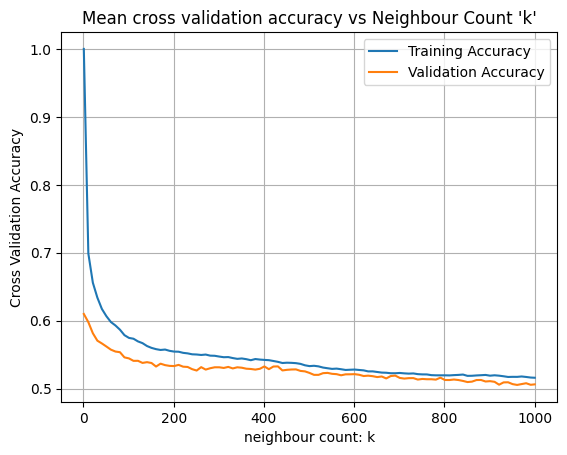

In [ ]:
plt.plot(k, mean_train_accuracy, label="Training Accuracy")
plt.plot(k, mean_val_accuracy, label="Validation Accuracy")
plt.xlabel("neighbour count: k")
plt.ylabel("Cross Validation Accuracy")
plt.title("Mean cross validation accuracy vs Neighbour Count 'k'")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
print("Highest CV Val Accuracy: ", max(mean_val_accuracy), "at k=", mean_val_accuracy.argmax()+1)

Highest CV Val Accuracy:  0.6098409310581481 at k= 1


## Part 3: Feature Selection [3 Marks]
In this part, we aim to investigate the importance of each feature on the final classification accuracy.
If we want to try every possible combination of features, we would have to test  $2^F$ different cases,  where F is the number of features, and in each case, we have to do a hyperparameter search (finding K, in KNN using cross-validation). That will take days!.

To find more important features we will use a decision tree. based on a decision tree we can compute feature importance that is a metric for our feature selection (code is provided below).

You can use [this link](https://machinelearningmastery.com/calculate-feature-importance-with-python/
) to get familiar with extracting the feature impotance order of machine learning algorithms in Python.

After we identified and removed the least important feature and evaluated a new KNN model on the new set of features, if the stop conditions (see step 7 below) are not met, we need to repeat the process and remove another feature.


Design a function ( `Feature_selector`) that accepts your dataset (X_train , y_train) and a threshold as inputs and: **[1]**
1. Fits a decision tree classifier on the training set.

2. Extracts the feature importance order of the decision tree model.

3. Removes the least important feature based on step 2.
4. Then, a KNN model is trained on the remaining features. The number of neighbors (`k`) for each KNN model should be tuned using a 5-fold cross-validation.
5. Store the best `mean cross-validation` score and the corresponding `k` (number of neighbours) value in two lists.
6. Go back to step 3 and follow all the steps until you meet the stop condition (step 7).

7. We will stop this process when (1) there is only one feature left, or (2) our cross-validation accuracy is dropped significantly compared to a model that uses all the features. In this function, we accept a threshold as an input argument. For example, if threshold=0.95 we do not continue removing features if our mean cross-validation accuracy after tuning `k` is bellow **0.95 $\times$ Full Feature cross-validation accuracy**.

8. Your function returns the list of removed features, and the corresponding mean cross-validation accuracy and `k` value when a feature was removed.

* Visualize your results by plotting the mean cross-validation accuracy (with a tuned `k` on y axis) vs. the number of features (x axis). This plot describes: what is the best cv score with 1 feature, 2 features, 3 features ... and all the features. **[0.5]**

* Plot the best value of `k` (y-axis) vs. the number of features. This plot explains the trend of number of neighbours with respect to the number of features.  **[0.5]**

* State what is the number of essential features for classification and justify your answer. **[1]**
  
  









**Answer: The highest cv accuracies are obtained when the number of features ranges from 4 to 5 as seen in the plots below since this is where the first graph peaks. For these number of features, the highest mean CV accuracy is returned (~87%) corresponding to k of 11. I selected 4 features to be the essential amount as the graph first reaches the highest accuracy of 87.24% here. By choosing 4, I can maintain a simpler model with fewer features, reducing any potential overfitting.**

You can use the following piece of code to start training a decision tree classifier and obtain its feature importance order.
```
from sklearn import tree
dt = tree.DecisionTreeClassifier()
dt.fit(X_train,y_train)
importance = dt.feature_importances_
```


In [6]:
from sklearn import neighbors
from sklearn.model_selection import cross_validate
import numpy as np
import matplotlib.pyplot as plt

In [7]:
def Feature_selector (X_train , y_train , tr=0.95):
### YOUR CODE HERE ###
  '''function outputs: removed features, corresponding mean cross validation accuracy and k value when a feature was removed'''
  from sklearn import tree

  #fit decision tree initially
  dt = tree.DecisionTreeClassifier()
  dt.fit(X_train, y_train)
  importance = dt.feature_importances_

  #output lists
  removed_features = ['']
  mean_cv_accs = []
  best_k_vals = []

  #to track number of features and get name of removed feature
  curr_features = list(X_train.columns)
  n_features = X_train.shape[1]

  #calculate mean CV acc and k for full features, append values to output lists
  full_k, full_mean_cv = findBestK(X_train, y_train)
  best_k_vals.append(full_k)
  mean_cv_accs.append(full_mean_cv)
  print("Removed Features: ", removed_features, " Best K: ", full_k, " Best Cross-Val Acc: ", full_mean_cv)

  #use while loop for stop condition: if there is more than 1 feature or the cv accuracy has greater than 95% of full feature accuracy
  while (n_features>1) and mean_cv_accs[-1] > tr*full_mean_cv:
    least_important_index = np.argmin(importance) #grab least important index
    removed_feature = curr_features[least_important_index] #get the name of the feature to be dropped
    print("Least important feature: ", removed_feature)
    removed_features.append(removed_feature) #store removed feature name in list
    X_train.drop(removed_feature, axis=1, inplace=True) #remove feature column from x_train_copy table
    curr_features.remove(removed_feature) #remove feature name from list
    #print(x_train_copy.columns)
    n_features -= 1 #decrease num features by 1
    print("num features: ", n_features)

    #tune knn and get CV accuracy with remaining features, add these values to the list
    k, mean_cv = findBestK(X_train, y_train)
    best_k_vals.append(k)
    mean_cv_accs.append(mean_cv)

    #refit tree and remaining features as the parameters have changed (i.e., # of features is NOT the same as previous iteration)
    dt.fit(X_train, y_train)
    importance = dt.feature_importances_
    print("Removed Features: ", removed_features, " Best K: ", k, " Best Cross-Val Acc: ", mean_cv)

  return removed_features, mean_cv_accs, best_k_vals

#helper function to find K (cleans up the code)
def findBestK(X_train, y_train):

  #set range of ks to search through for best accuracy
  range_k = np.arange(1,100,10)
  range_k = np.append(range_k,100)
  #print(range_k)
  best_k = 0
  best_mean = 0

  #tuning using 5 fold cross validation
  for i in range(len(range_k)):
    knn = neighbors.KNeighborsClassifier(n_neighbors=range_k[i])
    scores = cross_validate(knn, X_train, y_train, cv=5, return_train_score=True)
    mean_score = scores['test_score'].mean()
    print("k: ", range_k[i], " mean test accuracy: ", mean_score)
    #take the highest test score to return such that this is what gets appended to the output lists
    if mean_score > best_mean:
      best_mean = mean_score
      best_k = range_k[i]

  return best_k, best_mean

#copy of x_train as columns/features will be dropped
x_train_copy = x_train.copy()

removed_feats, best_cross_validates, best_ks = Feature_selector(x_train_copy, y_train)

k:  1  mean test accuracy:  0.6098409310581481
k:  11  mean test accuracy:  0.5977984503923126
k:  21  mean test accuracy:  0.5814644499299935
k:  31  mean test accuracy:  0.5705283254343825
k:  41  mean test accuracy:  0.566445208588597
k:  51  mean test accuracy:  0.5619458128373822
k:  61  mean test accuracy:  0.5573090627736037
k:  71  mean test accuracy:  0.5545403217789466
k:  81  mean test accuracy:  0.5535717510998047
k:  91  mean test accuracy:  0.5459579289537573
k:  100  mean test accuracy:  0.5459578570906709
Removed Features:  ['']  Best K:  1  Best Cross-Val Acc:  0.6098409310581481
Least important feature:  Population
num features:  7
k:  1  mean test accuracy:  0.8183138764026776
k:  11  mean test accuracy:  0.8440618214178347
k:  21  mean test accuracy:  0.8460002323573128
k:  31  mean test accuracy:  0.8401169691503748
k:  41  mean test accuracy:  0.8399786327089629
k:  51  mean test accuracy:  0.8363106689135857
k:  61  mean test accuracy:  0.8346496015790716
k:  71 

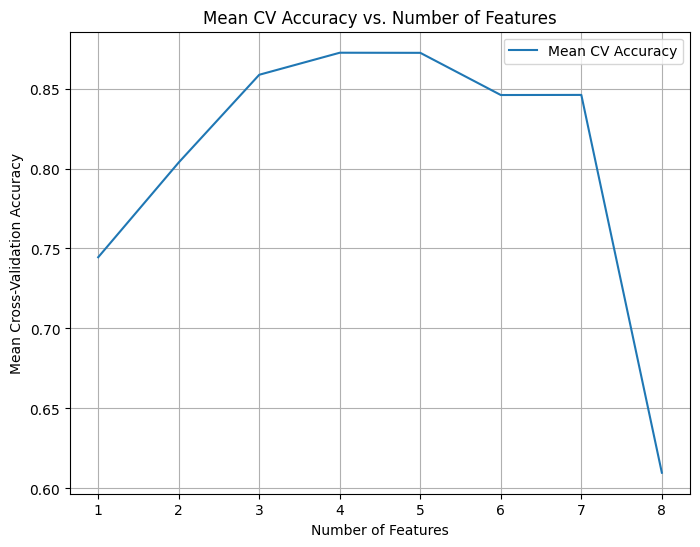

In [8]:
#plot mean cv accuracy with tuned k vs num of features
#create a list of the num of features remaining after each iteration
num_features_left = [len(x_train.columns) - i for i in range(len(removed_feats))]
plt.figure(figsize=(8,6))
plt.plot(num_features_left, best_cross_validates, label='Mean CV Accuracy')

plt.xlabel('Number of Features')
plt.ylabel('Mean Cross-Validation Accuracy')
plt.title('Mean CV Accuracy vs. Number of Features')
plt.grid(True)
plt.legend()
plt.show()

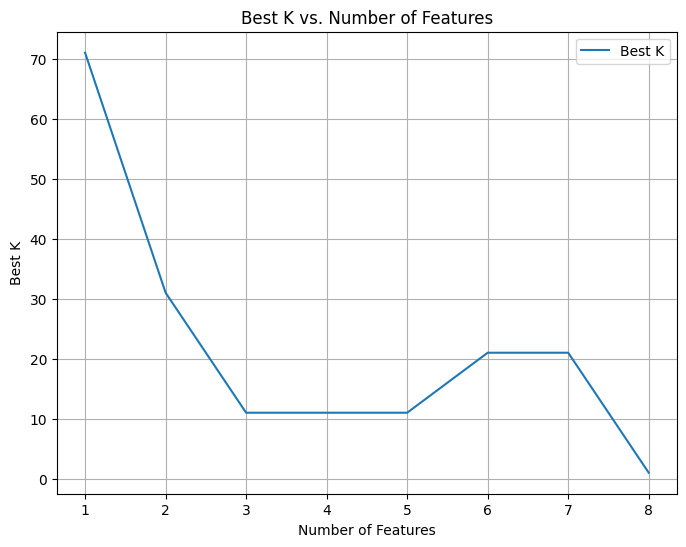

In [9]:
#plot best k vs num features left
plt.figure(figsize=(8,6))
plt.plot(num_features_left, best_ks, label='Best K')

plt.xlabel('Number of Features')
plt.ylabel('Best K')
plt.title('Best K vs. Number of Features')
plt.grid(True)
plt.legend()
plt.show()

## Part 4: Standardization [1 Marks]

Standardizing the data usually means scaling our data to have a mean of zero and a standard deviation of one.

**Note:** When we standardize a dataset, do we care if the data points are in our training set or test set? Yes! The training set is available for us to train a model - we can use it however we want. The test set, however, represents a subset of data that is not available for us during training. For example, the test set can represent the data that someone who bought our model would use to see how the model performs (which they are not willing to share with us).
Therefore, we cannot compute the mean or standard deviation of the whole dataset to standardize it - we can only calculate the mean and standard deviation of the training set. However, when we sell a model to someone, we can say what our scalers (mean and standard deviation of our training set) was. They can scale their data (test set) with our training set's mean and standard deviation. Of course, there is no guarantee that the test set would have a mean of zero and a standard deviation of one, but it should work fine.

**To summarize: We fit the StandardScaler only on the training set. We transform both training and test sets with that scaler.**

1. Standardize the training  and test data ([Help](https://scikit-learn.org/stable/modules/preprocessing.html))

2. Call your ``Feature_selector`` function on the standardized training data with a threshold of 95\%.
 * Plot the Cross validation accuracy when we have the standardized data (this part) and the original training data (last part) vs. the Number of features in a single plot (to compare them easily).

3. Discuss how standardization (helped/hurt) your model and its performance? Discuss which cases lead to a higher cross validation accuracy (how many features? which features? What K?)

**Answer: Standardization helped the model by increasing the cross validation accuracy at num features = 4 by around 0.5% and at n=8 significantly by 20%. Generally, it performed the same/marginally better at all other points. However, standardization didnt help at k=5, showing a worse performance by about 1%.
Four features continued to show the highest CV accuracy. These important features include: Median Income (MedInc), Longitude, Latitude, and Average Occupancy. These features are important as they likely contribute to more meaningful distance based comparisons in relation to being above/below the median house value. Standardizing also helped improve the accuracy at n=8 (full feature), as it likely reduced the bias of very large scale values - such as population whose values ranged in the 100s to around 35000 maximum. The k value remained at 11 from 3 to 7 features which may suggest that it was able to find a balance between bias and variance.**

In [10]:
### YOUR CODE HERE ###
from sklearn.preprocessing import StandardScaler

#initialize standard scaler
scaler = StandardScaler()

#fit and transform the training data, and transform the test data
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

#convert the scaled NumPy arrays back into pandas DataFrames to pass into feature selector function
x_train_scaled_df = pd.DataFrame(x_train_scaled, columns=x_train.columns)
x_test_scaled_df = pd.DataFrame(x_test_scaled, columns=x_test.columns)

removed_feats_scaled, best_cross_validates_scaled, best_ks_scaled = Feature_selector(x_train_scaled_df, y_train)

k:  1  mean test accuracy:  0.807102037198729
k:  11  mean test accuracy:  0.8331953322529916
k:  21  mean test accuracy:  0.8343719226130375
k:  31  mean test accuracy:  0.8334032561164468
k:  41  mean test accuracy:  0.8312573285376701
k:  51  mean test accuracy:  0.8285578635583487
k:  61  mean test accuracy:  0.8245432561883101
k:  71  mean test accuracy:  0.8244740520360608
k:  81  mean test accuracy:  0.822882069081985
k:  91  mean test accuracy:  0.822466963940301
k:  100  mean test accuracy:  0.8197674750066174
Removed Features:  ['']  Best K:  21  Best Cross-Val Acc:  0.8343719226130375
Least important feature:  Population
num features:  7
k:  1  mean test accuracy:  0.8205280020504935
k:  11  mean test accuracy:  0.8493914993155041
k:  21  mean test accuracy:  0.8481456089857604
k:  31  mean test accuracy:  0.8448925586971701
k:  41  mean test accuracy:  0.8402549702307164
k:  51  mean test accuracy:  0.8391475361141951
k:  61  mean test accuracy:  0.8364481669523224
k:  71  

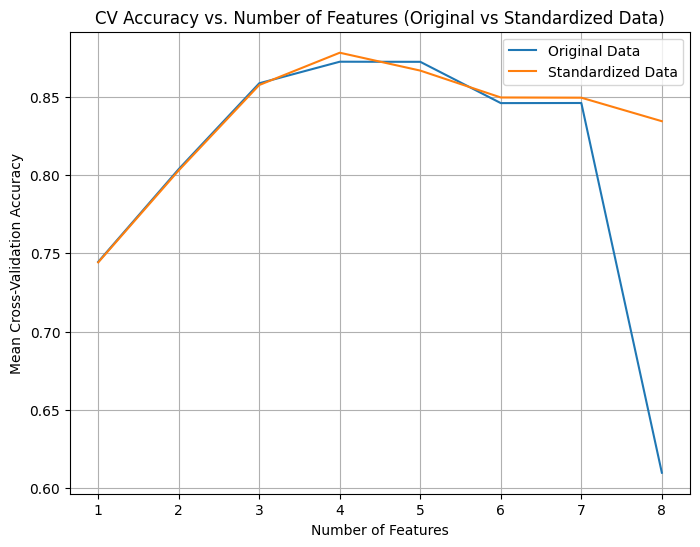

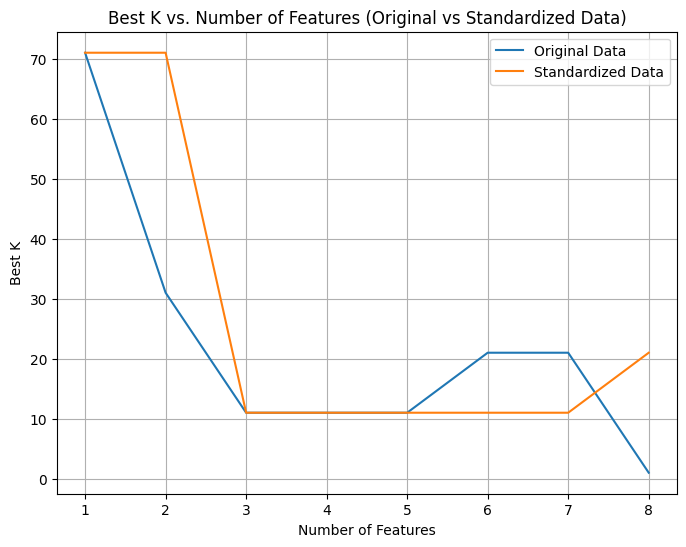

In [11]:
# plot mean cv accuracy for both original and standardized data
plt.figure(figsize=(8,6))
plt.plot(num_features_left, best_cross_validates, label='Original Data')
plt.plot(num_features_left, best_cross_validates_scaled,  label='Standardized Data')

plt.xlabel('Number of Features')
plt.ylabel('Mean Cross-Validation Accuracy')
plt.title('CV Accuracy vs. Number of Features (Original vs Standardized Data)')
plt.grid(True)
plt.legend()

plt.show()

plt.figure(figsize=(8,6))
plt.plot(num_features_left, best_ks, label='Original Data')
plt.plot(num_features_left, best_ks_scaled,  label='Standardized Data')

plt.xlabel('Number of Features')
plt.ylabel('Best K')
plt.title('Best K vs. Number of Features (Original vs Standardized Data)')
plt.grid(True)
plt.legend()

plt.show()


## Part 5: Decision Tree Classifier [1 Mark]

Train a decision tree classifier on the standardized dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) and check the example there.) Tune the `max_depth` and `min_samples_split` parameters of the tree using cross-validation (CV).
 * Compare the decision tree's performance (mean CV score) with KNN, both using all the features.


**Answer: For a full feature set, the Decision Tree returned an overall higher mean-cross validation accuracy in comparison to the KNN by almost 2%**

In [15]:
### YOUR CODE HERE ###
from sklearn import tree
#initialize standard scaler
scaler = StandardScaler()

#fit and transform the training data - other one has columns dropped from previous step
x_train_scaled_dt = scaler.fit_transform(x_train)

x_train_scaled_dt_df = pd.DataFrame(x_train_scaled_dt, columns=x_train.columns)

#set up 2 arrays of hyperparams to tune
max_depth_list = np.arange(1,20,1)
min_samples_split_list = np.arange(2,20,1) #parameter starts at 2
mean_cv_acc_list = [] #2D array storing the max_depth, min_samples_split and mean CV score

#tune training data on decision tree to get results to store in 2D array (using 5 fold cross validation)
for i in range(len(max_depth_list)):
  for j in range(len(min_samples_split_list)):
    dt_class = tree.DecisionTreeClassifier(max_depth=max_depth_list[i], min_samples_split=min_samples_split_list[j])
    dt_class.fit(x_train_scaled_dt_df, y_train)
    dt_scores = cross_validate(dt_class, x_train_scaled_dt_df, y_train, cv=5, return_train_score=True)
    mean_cv_score = dt_scores['test_score'].mean()
    print("Max Depth: ", max_depth_list[i], " Min Samples Split: ", min_samples_split_list[j], " Mean CV Score: ", mean_cv_score)
    mean_cv_acc_list.append([max_depth_list[i], min_samples_split_list[j], mean_cv_score])

#find maximum cv score in 2D array
best_params = max(mean_cv_acc_list, key=lambda x: x[2])
print("Best Params: ", best_params)

best_depth = best_params[0]
best_split = best_params[1]
print("Best Depth: ", best_depth)
print("Best Split: ", best_split)

#decision tree with best params
best_tree = tree.DecisionTreeClassifier(max_depth=best_depth, min_samples_split=best_split)

#best knn
best_knn = neighbors.KNeighborsClassifier(n_neighbors=11)

#get scores of both
tree_score = cross_validate(best_tree, x_train_scaled_dt_df, y_train, cv=5, return_train_score=True)
tree_mean_cv = tree_score['test_score'].mean()
knn_score = cross_validate(best_knn, x_train_scaled_dt_df, y_train, cv=5, return_train_score=True)
knn_mean_cv = knn_score['test_score'].mean()

print("Decision Tree Mean CV Accuracy: ", tree_mean_cv)
print("KNN Mean CV Accuracy: ", knn_mean_cv)

Max Depth:  1  Min Samples Split:  2  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  3  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  4  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  5  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  6  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  7  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  8  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  9  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  10  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  11  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  12  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  13  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  14  Mean CV Score:  0.7389263654884713
Max Depth:  1  Min Samples Split:  15  Mean CV

## Part 6: Test Data [0.5 Mark]

Now that you've created several models, pick your best one (highest CV accuracy) and apply it to the test dataset you had initially set aside. Discuss your results.

In [18]:
### YOUR CODE HERE ###
#best model is KNN with 4 features left: Removed Features:  ['', 'Population', 'HouseAge', 'AveBedrms', 'AveRooms']  Best K:  11  Best Cross-Val Acc:  0.8781147916988553
#features required: 'MedInc', 'AveOccup','Latitude','Longitude'
from sklearn.metrics import accuracy_score

x_train_scaled_df_final = x_train_scaled_dt_df[['MedInc', 'AveOccup','Latitude','Longitude']]
x_test_scaled_df = x_test_scaled_df[['MedInc', 'AveOccup','Latitude','Longitude']]
#derived from Tutorial: Basic Data Science code
best_model = neighbors.KNeighborsClassifier(n_neighbors=11)
best_model.fit(x_train_scaled_df_final, y_train)

accuracy = accuracy_score(y_test, best_model.predict(x_test_scaled_df))
print ("Test set accuracy: ", accuracy * 100, "%")

Test set accuracy:  87.82299741602067 %


**Answer: The best model was the KNN with scaled data that had 4 essential features. The final model had a test accuracy of 87.82% which was slightly better than the validation accuracy of 87.81%. This suggests that the model is generalizing well to unseen data and does not show any apparent signs of overfitting/high variance. Reducing the feature set to 4 key features did not negatively impact the model's performance. Feature selection likely helped simplify the model by focusing on more important predictors, allowing potential noise from less relevant features to be reduced. One such noise would be outliers in the data, as noticed when plotting Population vs Latitude that there are some values significantly larger than the rest. The optimal k=11 value provided the best CV accuracy as KNNs with a larger k are generally more stable and prone to less noise when making predictions, also positively contributing to the models ability to generalize. **

In [19]:
%%shell
jupyter nbconvert --to html /content/TiffanyCostas_F24_APS1070_Project_1.ipynb

[NbConvertApp] Converting notebook /content/TiffanyCostas_F24_APS1070_Project_1.ipynb to html
[NbConvertApp] Writing 1126732 bytes to /content/TiffanyCostas_F24_APS1070_Project_1.html


References:

https://towardsdatascience.com/decision-trees-in-machine-learning-641b9c4e8052

https://www.analyticsvidhya.com/blog/2021/02/machine-learning-101-decision-tree-algorithm-for-classification/